# **2.1. Метод простой итерации и метод Ньютона решения нелинейных уравнений**

In [8]:
import numpy as np
import matplotlib.pyplot as plt

In [9]:
# Исходная функция и ее производная
def f(x):
    return x**3 + x**2 - 2*x - 1

def df(x):
    return 3*x**2 + 2*x - 2

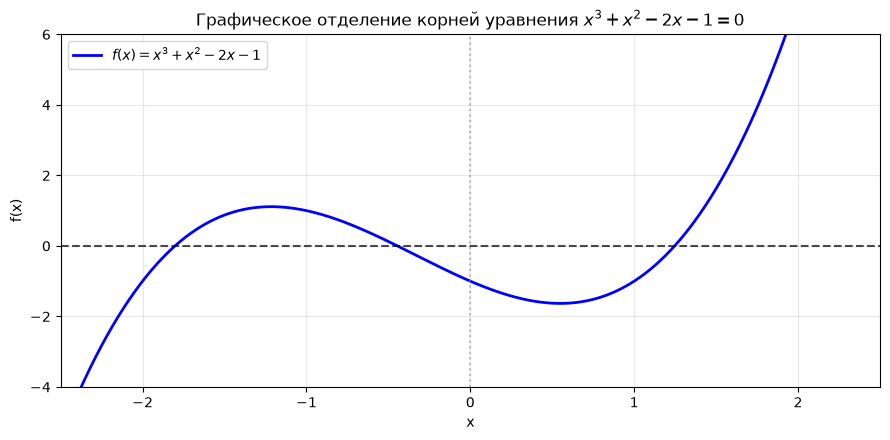

In [10]:
x_vals = np.linspace(-2.5, 2.5, 1000)

plt.figure(figsize=(9, 4.5))
plt.plot(x_vals, f(x_vals), label=r"$f(x) = x^3 + x^2 - 2x - 1$", color="blue", lw=2)
plt.axhline(0, color="black", linestyle="--", alpha=0.7)
plt.axvline(0, color="gray", linestyle=":", alpha=0.5)
plt.grid(True, alpha=0.3)
plt.title("Графическое отделение корней уравнения $x^3 + x^2 - 2x - 1 = 0$")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.xlim(-2.5, 2.5)
plt.ylim(-4, 6)
plt.legend()
plt.tight_layout()
plt.savefig("root_localization.png", dpi=150)
plt.show()

In [22]:
# Отрезок локализации корня [1, 2]
# f'(1) = 3, f'(2) = 14 -> m1 = 3, M1 = 14
LAMBDA = 2.0 / (14.0 + 3.0)  
Q_EST = (14.0 - 3.0) / (14.0 + 3.0)  

def phi(x):
    return x - LAMBDA * f(x)

def simple_iteration(x0, eps, max_iter=200):
    history_x = [x0]
    history_diff = []
    
    x_curr = x0
    for _ in range(max_iter):
        x_next = phi(x_curr)
        diff = abs(x_next - x_curr)
        history_x.append(x_next)
        history_diff.append(diff)
        
        if diff <= (1 - Q_EST) / Q_EST * eps or diff <= eps:
            break
        x_curr = x_next
        
    return history_x, history_diff

def newton_method(x0, eps, max_iter=100):
    history_x = [x0]
    history_diff = []
    
    x_curr = x0
    for _ in range(max_iter):
        f_val = f(x_curr)
        df_val = df(x_curr)
        if abs(df_val) < 1e-14:
            raise ZeroDivisionError("Производная близка к нулю")
        x_next = x_curr - f_val / df_val
        diff = abs(x_next - x_curr)
        history_x.append(x_next)
        history_diff.append(diff)
        
        if diff <= eps:
            break
        x_curr = x_next
        
    return history_x, history_diff

def main():
    eps_str = input("Введите точность вычислений epsilon (например, 1e-5): ").strip()
    eps = float(eps_str) if eps_str else 1e-5
    
    x0 = 1.5
    
    hist_iter, diff_iter = simple_iteration(x0, eps)
    hist_newt, diff_newt = newton_method(x0, eps)
    
    print("\n" + "="*60)
    print("РЕЗУЛЬТАТЫ ВЫЧИСЛЕНИЙ")
    print("="*60)
    print(f"Заданная точность: eps = {eps}")
    print(f"Начальное приближение: x0 = {x0}")
    print("-" * 60)
    print("Метод простой итерации:")
    print(f"  Найденный корень: x* = {hist_iter[-1]:.8f}")
    print(f"  Количество итераций: {len(diff_iter)}")
    print(f"  f(x*): {f(hist_iter[-1]):.2e}")
    print("-" * 60)
    print("Метод Ньютона:")
    print(f"  Найденный корень: x* = {hist_newt[-1]:.8f}")
    print(f"  Количество итераций: {len(diff_newt)}")
    print(f"  f(x*): {f(hist_newt[-1]):.2e}")
    print("="*60)

    # 2. Построение графика зависимости погрешности от номера итерации
    plt.figure(figsize=(9, 4.5))
    plt.plot(range(1, len(diff_iter) + 1), diff_iter, marker='o', label="Метод простой итерации", color="orange")
    plt.plot(range(1, len(diff_newt) + 1), diff_newt, marker='s', label="Метод Ньютона", color="teal")
    plt.axhline(eps, color="red", linestyle="--", label=f"Порог $\\varepsilon = {eps}$")
    plt.yscale("log")
    plt.grid(True, which="both", alpha=0.3)
    plt.title("Зависимость погрешности $|x_{k+1} - x_k|$ от номера итерации")
    plt.xlabel("Номер итерации (k)")
    plt.ylabel("Погрешность $|x_{k+1} - x_k|$")
    plt.legend()
    plt.tight_layout()
    plt.savefig("error_analysis.png", dpi=150)
    plt.show()

Введите точность вычислений epsilon (например, 1e-5):  1e-6



РЕЗУЛЬТАТЫ ВЫЧИСЛЕНИЙ
Заданная точность: eps = 1e-06
Начальное приближение: x0 = 1.5
------------------------------------------------------------
Метод простой итерации:
  Найденный корень: x* = 1.24697989
  Количество итераций: 14
  f(x*): 1.48e-06
------------------------------------------------------------
Метод Ньютона:
  Найденный корень: x* = 1.24697960
  Количество итераций: 5
  f(x*): 8.88e-16


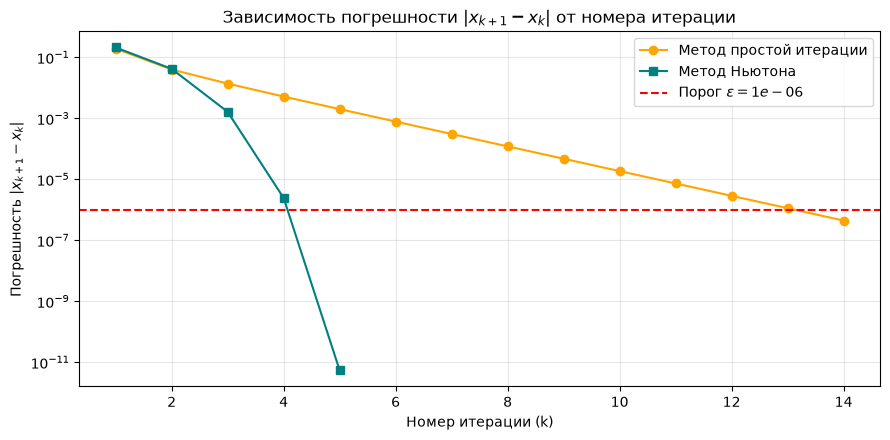

In [23]:
main()

---
# **2.2. Метод простой итерации и метод Ньютона для решения систем нелинейных уравнений**

In [13]:
a = 4.0

def F(x):
    return np.array([
        x[0]**2 + x[1]**2 - a**2,
        x[0] - np.exp(x[1]) + a
    ], dtype=float)

def J(x):
    return np.array([
        [2.0 * x[0], 2.0 * x[1]],
        [1.0, -np.exp(x[1])]
    ], dtype=float)

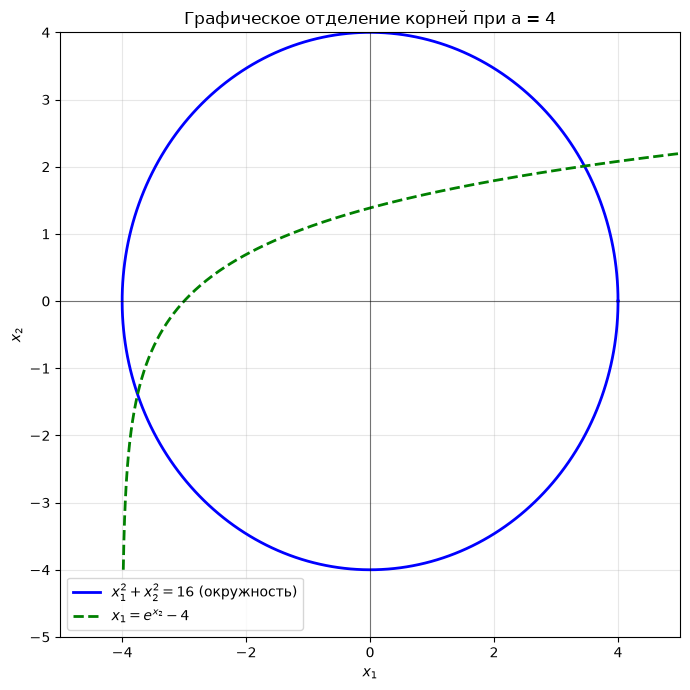

In [14]:
x2_vals = np.linspace(-4, 3, 500)
x1_curve = np.exp(x2_vals) - a
theta = np.linspace(0, 2 * np.pi, 500)
x1_circ = a * np.cos(theta)
x2_circ = a * np.sin(theta)

plt.figure(figsize=(7, 7))
plt.plot(x1_circ, x2_circ, 'b-', label=r'$x_1^2 + x_2^2 = 16$ (окружность)', lw=2)
plt.plot(x1_curve, x2_vals, 'g--', label=r'$x_1 = e^{x_2} - 4$', lw=2)
plt.axhline(0, color='black', lw=0.8, alpha=0.5)
plt.axvline(0, color='black', lw=0.8, alpha=0.5)
plt.xlim(-5, 5)
plt.ylim(-5, 4)
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.title('Графическое отделение корней при a = 4')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('system_root_localization.png', dpi=150)
plt.show()

In [26]:
def solve_newton(x0, eps, max_iter=100):
    xk = np.array(x0, dtype=float)
    diffs = []
    xs = [xk.copy()]
    
    for _ in range(max_iter):
        Jx = J(xk)
        Fx = F(xk)
        
        delta = np.linalg.solve(Jx, -Fx)
        x_next = xk + delta
        diff = np.linalg.norm(delta, ord=np.inf)
        diffs.append(diff)
        xs.append(x_next.copy())
        
        if diff <= eps:
            break
        xk = x_next
        
    return xs, diffs

def solve_simple_iteration(x0, eps, max_iter=300):
    xk = np.array(x0, dtype=float)
    Lambda = np.linalg.inv(J(x0))
    diffs = []
    xs = [xk.copy()]
    
    for _ in range(max_iter):
        x_next = xk - Lambda @ F(xk)
        diff = np.linalg.norm(x_next - xk, ord=np.inf)
        diffs.append(diff)
        xs.append(x_next.copy())
        
        if diff <= eps:
            break
        xk = x_next
        
    return xs, diffs

def main():
    eps_input = input("Введите точность вычислений epsilon (например, 1e-6): ").strip()
    eps = float(eps_input) if eps_input else 1e-6
    x0 = np.array([3.5, 2.0])
    
    xs_n, diffs_n = solve_newton(x0, eps)
    xs_i, diffs_i = solve_simple_iteration(x0, eps)

    root_newton = xs_n[-1]
    root_iter = xs_i[-1]

    print("\n" + "="*60)
    print("РЕЗУЛЬТАТЫ ВЫЧИСЛЕНИЙ СИСТЕМЫ")
    print("="*60)
    print(f"Заданная точность: eps = {eps}")
    print(f"Начальное приближение: x0 = {x0.tolist()}")
    print("-" * 60)
    print("Метод простой итерации:")
    print(f"  Корень: x1 = {root_iter[0]:.8f}, x2 = {root_iter[1]:.8f}")
    print(f"  Число итераций: {len(diffs_i)}")
    print("-" * 60)
    print("Метод Ньютона:")
    print(f"  Корень: x1 = {root_newton[0]:.8f}, x2 = {root_newton[1]:.8f}")
    print(f"  Число итераций: {len(diffs_n)}")
    print("="*60)

    plt.figure(figsize=(8, 4.5))
    plt.plot(range(1, len(diffs_i) + 1), diffs_i, 'o-', color='orange', label='Метод простой итерации')
    plt.plot(range(1, len(diffs_n) + 1), diffs_n, 's-', color='teal', label='Метод Ньютона')
    plt.axhline(eps, color='red', linestyle='--', label=f'Порог точности $\\varepsilon = {eps}$')
    plt.yscale('log')
    plt.xlabel('Номер итерации (k)')
    plt.ylabel(r'Погрешность $\|x^{(k+1)} - x^{(k)}\|_\infty$')
    plt.title('Зависимость погрешности от номера итерации')
    plt.grid(True, which='both', alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig('system_error_analysis.png', dpi=150)
    plt.show()

Введите точность вычислений epsilon (например, 1e-6):  1e-7



РЕЗУЛЬТАТЫ ВЫЧИСЛЕНИЙ СИСТЕМЫ
Заданная точность: eps = 1e-07
Начальное приближение: x0 = [3.5, 2.0]
------------------------------------------------------------
Метод простой итерации:
  Корень: x1 = 3.45867073, x2 = 2.00937721
  Число итераций: 4
------------------------------------------------------------
Метод Ньютона:
  Корень: x1 = 3.45867073, x2 = 2.00937721
  Число итераций: 3


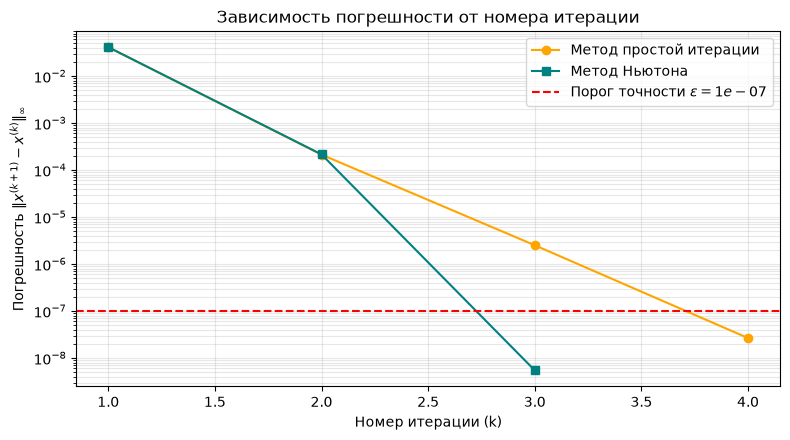

In [27]:
main()